In [ ]:
# IMPORTANT: RUN THIS CELL IN ORDER TO IMPORT YOUR KAGGLE DATA SOURCES,
# THEN FEEL FREE TO DELETE THIS CELL.
# NOTE: THIS NOTEBOOK ENVIRONMENT DIFFERS FROM KAGGLE'S PYTHON
# ENVIRONMENT SO THERE MAY BE MISSING LIBRARIES USED BY YOUR
# NOTEBOOK.
import kagglehub
kelkalot_the_hyper_kvasir_dataset_path = kagglehub.dataset_download('kelkalot/the-hyper-kvasir-dataset')

print('Data source import complete.')


In [ ]:

print("Python is working!")

import tensorflow as tf
print(tf.__version__)


Python is working!
2.20.0


In [ ]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU available:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU'), PhysicalDevice(name='/physical_device:GPU:1', device_type='GPU')]


In [ ]:
import os

print(os.listdir("/kaggle/input"))

['datasets']


In [ ]:
import os

dataset_path = "/kaggle/input/datasets"

print(os.listdir(dataset_path))

['kelkalot']


In [ ]:
import os

dataset_path = "/kaggle/input/datasets/kelkalot"

print(os.listdir(dataset_path))

['the-hyper-kvasir-dataset']


In [ ]:

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, Xception
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input as mobilenet_preprocess
from tensorflow.keras.applications.xception import preprocess_input as xception_preprocess
from tensorflow.keras.callbacks import EarlyStopping

print("TensorFlow:", tf.__version__)
print("GPUs:", len(tf.config.list_physical_devices("GPU")))

# Dataset location
DATASET_ROOT = "/kaggle/input/datasets/kelkalot"

# Training settings
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
EPOCHS = 5
MAX_IMAGES_PER_CLASS = 100

SEED = 42
tf.random.set_seed(SEED)
np.random.seed(SEED)

print("Setup completed successfully!")


TensorFlow: 2.20.0
GPUs: 2
Setup completed successfully!


In [ ]:

import os

DATASET_ROOT = "/kaggle/input/datasets/kelkalot"

for root, dirs, files in os.walk(DATASET_ROOT):
    level = root.replace(DATASET_ROOT, "").count(os.sep)

    if level <= 2:
        print(
            "  " * level,
            os.path.basename(root) or root,
            "| folders:", len(dirs),
            "| files:", len(files)
        )

    if level >= 2:
        dirs[:] = []


 kelkalot | folders: 1 | files: 0
   the-hyper-kvasir-dataset | folders: 4 | files: 1
     labeled-images | folders: 2 | files: 1
     unlabeled-images | folders: 1 | files: 0
     labeled-videos | folders: 2 | files: 1
     segmented-images | folders: 2 | files: 1


In [ ]:

import os

DATASET_ROOT = "/kaggle/input/datasets/kelkalot"

for item in os.listdir(DATASET_ROOT):
    path = os.path.join(DATASET_ROOT, item)
    print(item, "->", "Folder" if os.path.isdir(path) else "File")

    if os.path.isdir(path):
        print("  Contents:", os.listdir(path)[:10])


the-hyper-kvasir-dataset -> Folder
  Contents: ['labeled-images', 'unlabeled-images', 'license.txt', 'labeled-videos', 'segmented-images']


In [ ]:

import os

DATASET_ROOT = "/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset"
IMAGE_FOLDER = os.path.join(DATASET_ROOT, "labeled-images")

print("Labeled images path:", IMAGE_FOLDER)
print("Number of class folders:", len(os.listdir(IMAGE_FOLDER)))
print("\nClass folders:")

for folder in sorted(os.listdir(IMAGE_FOLDER)):
    path = os.path.join(IMAGE_FOLDER, folder)
    if os.path.isdir(path):
        print(folder, ":", len(os.listdir(path)), "items")


Labeled images path: /kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images
Number of class folders: 3

Class folders:
lower-gi-tract : 4 items
upper-gi-tract : 2 items


In [ ]:

import tensorflow as tf

IMAGE_SIZE = (224, 224)
BATCH_SIZE = 32
MAX_IMAGES_PER_CLASS = 100
SEED = 42

train_ds = tf.keras.utils.image_dataset_from_directory(
    IMAGE_FOLDER,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    IMAGE_FOLDER,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", num_classes)
print("Class names:", class_names)
print("Image size:", IMAGE_SIZE)


Found 10662 files belonging to 2 classes.
Using 8530 files for training.


I0000 00:00:1791642949.639145      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1791642949.644418      49 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 10662 files belonging to 2 classes.
Using 2132 files for validation.
Classes: 2
Class names: ['lower-gi-tract', 'upper-gi-tract']
Image size: (224, 224)


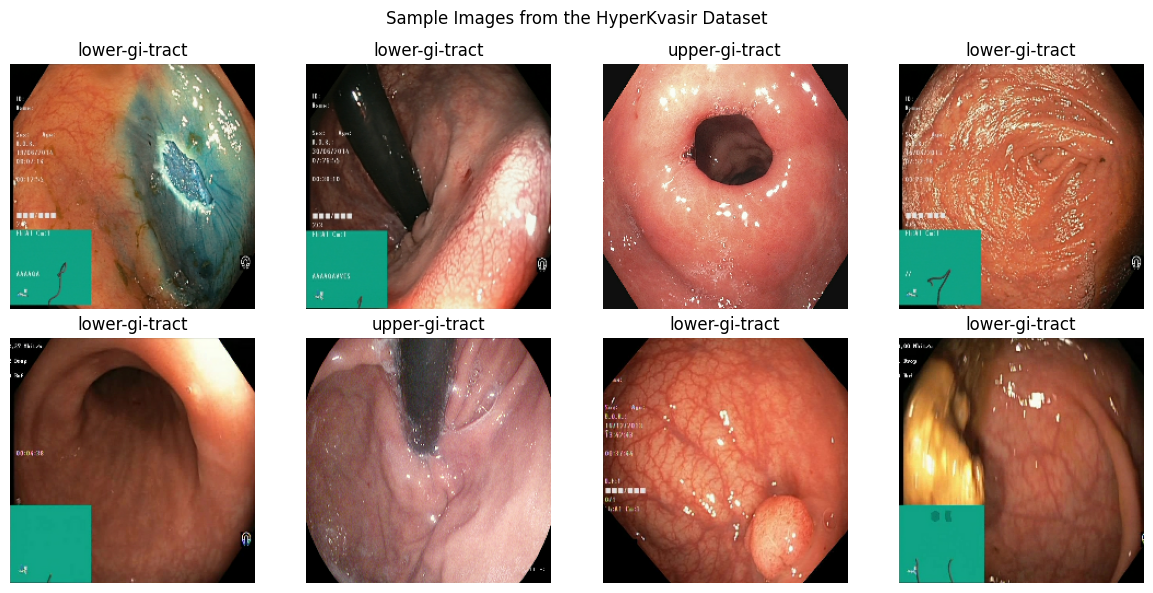

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for images, labels in train_ds.take(1):
    for i in range(min(8, len(images))):
        plt.subplot(2, 4, i + 1)
        plt.imshow(images[i].numpy().astype("uint8"))
        plt.title(class_names[int(labels[i].numpy())])
        plt.axis("off")

plt.suptitle("Sample Images from the HyperKvasir Dataset")
plt.tight_layout()

plt.savefig(
    "/kaggle/working/assignment_graphs/sample_dataset_images.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

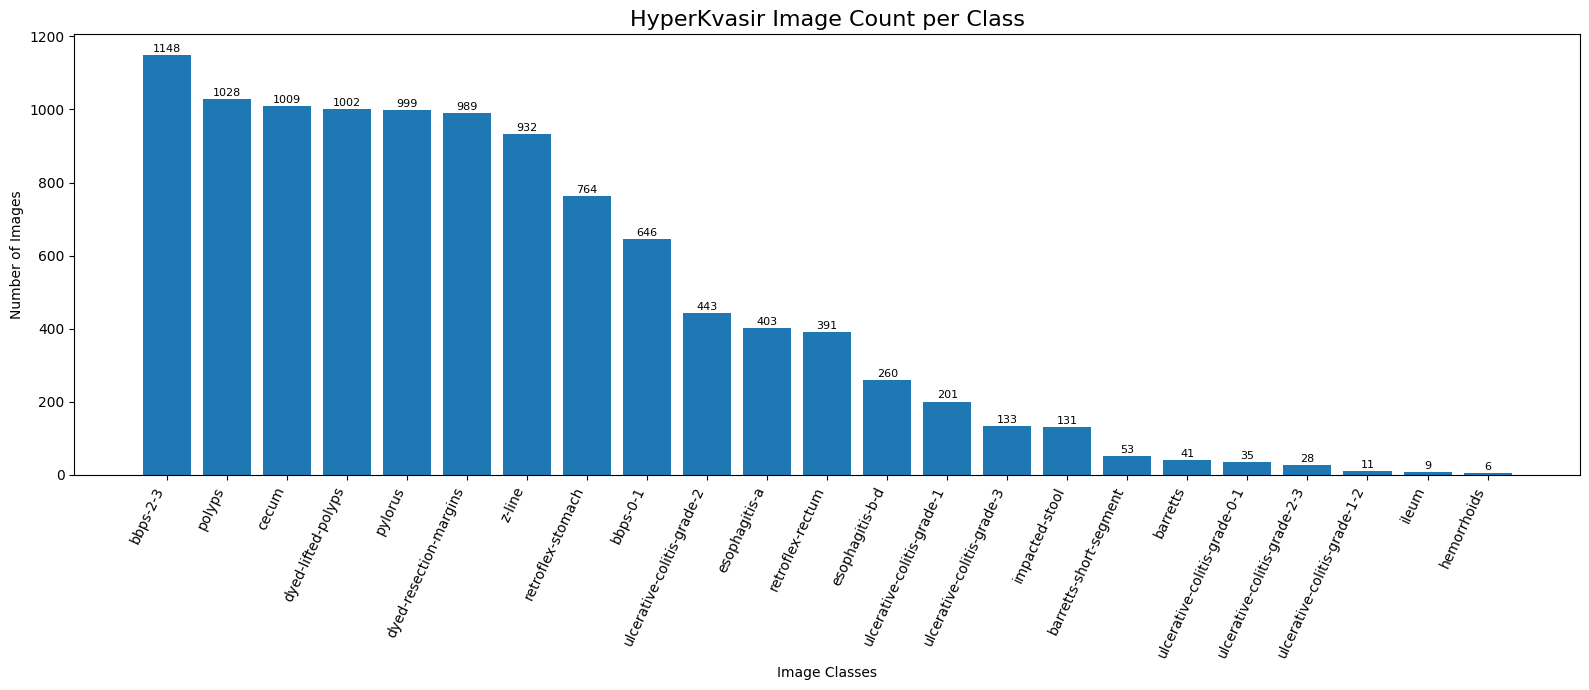

Categories: 23
Total images counted: 10662


In [ ]:

import os
import matplotlib.pyplot as plt

IMAGE_FOLDER = "/kaggle/input/datasets/kelkalot/the-hyper-kvasir-dataset/labeled-images"

# Find individual category folders recursively
class_counts = {}

for root, dirs, files in os.walk(IMAGE_FOLDER):
    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
    ]

    if image_files:
        category = os.path.basename(root)
        class_counts[category] = class_counts.get(category, 0) + len(image_files)

# Sort largest to smallest
class_counts = dict(
    sorted(class_counts.items(), key=lambda item: item[1], reverse=True)
)

# Plot like your reference
plt.figure(figsize=(16, 7))
bars = plt.bar(class_counts.keys(), class_counts.values())

plt.title("HyperKvasir Image Count per Class", fontsize=16)
plt.xlabel("Image Classes")
plt.ylabel("Number of Images")
plt.xticks(rotation=65, ha="right")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height + 3,
        str(int(height)),
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()

os.makedirs("/kaggle/working/assignment_graphs", exist_ok=True)
plt.savefig(
    "/kaggle/working/assignment_graphs/hyperkvasir_class_distribution.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print("Categories:", len(class_counts))
print("Total images counted:", sum(class_counts.values()))


In [ ]:

AUTOTUNE = tf.data.AUTOTUNE

train_ds = train_ds.cache().prefetch(buffer_size=AUTOTUNE)
val_ds = val_ds.cache().prefetch(buffer_size=AUTOTUNE)

print("Training batches:", tf.data.experimental.cardinality(train_ds).numpy())
print("Validation batches:", tf.data.experimental.cardinality(val_ds).numpy())
print("Dataset pipeline is ready!")


Training batches: 267
Validation batches: 67
Dataset pipeline is ready!


In [ ]:

from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

# Load pretrained MobileNetV2
base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

# Freeze pretrained layers
base_model.trainable = False

# Build classification model
mobilenet_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

# Compile model
mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

mobilenet_model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 2)              │         2,562 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,260,546 (8.62 MB)

 Trainable params: 2,562 (10.01 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=5,
    callbacks=[early_stop],
    verbose=1
)

print("MobileNetV2 training completed!")


Epoch 1/5


2026-10-10 14:38:24.170792: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-10 14:38:24.308559: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-10 14:38:24.445311: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1791643106.566952     162 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


266/267 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step - accuracy: 0.9366 - loss: 0.1540

2026-10-10 14:39:12.215697: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-10 14:39:12.354341: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


267/267 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step - accuracy: 0.9367 - loss: 0.1537

2026-10-10 14:39:35.722221: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-10-10 14:39:35.860174: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


267/267 ━━━━━━━━━━━━━━━━━━━━ 90s 267ms/step - accuracy: 0.9746 - loss: 0.0700 - val_accuracy: 0.9911 - val_loss: 0.0271
Epoch 2/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9933 - loss: 0.0248 - val_accuracy: 0.9948 - val_loss: 0.0229
Epoch 3/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9946 - loss: 0.0180 - val_accuracy: 0.9948 - val_loss: 0.0202
Epoch 4/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9953 - loss: 0.0149 - val_accuracy: 0.9948 - val_loss: 0.0192
Epoch 5/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 8s 30ms/step - accuracy: 0.9953 - loss: 0.0152 - val_accuracy: 0.9953 - val_loss: 0.0184
MobileNetV2 training completed!


In [ ]:

print("MobileNetV2 Results")
print("-" * 30)

for i in range(len(mobilenet_history.history["accuracy"])):
    print(f"Epoch {i+1}:")
    print(f"  Training Accuracy:   {mobilenet_history.history['accuracy'][i]*100:.2f}%")
    print(f"  Validation Accuracy: {mobilenet_history.history['val_accuracy'][i]*100:.2f}%")
    print(f"  Training Loss:       {mobilenet_history.history['loss'][i]:.4f}")
    print(f"  Validation Loss:     {mobilenet_history.history['val_loss'][i]:.4f}")


MobileNetV2 Results
------------------------------
Epoch 1:
  Training Accuracy:   97.46%
  Validation Accuracy: 99.11%
  Training Loss:       0.0700
  Validation Loss:     0.0271
Epoch 2:
  Training Accuracy:   99.33%
  Validation Accuracy: 99.48%
  Training Loss:       0.0248
  Validation Loss:     0.0229
Epoch 3:
  Training Accuracy:   99.46%
  Validation Accuracy: 99.48%
  Training Loss:       0.0180
  Validation Loss:     0.0202
Epoch 4:
  Training Accuracy:   99.53%
  Validation Accuracy: 99.48%
  Training Loss:       0.0149
  Validation Loss:     0.0192
Epoch 5:
  Training Accuracy:   99.53%
  Validation Accuracy: 99.53%
  Training Loss:       0.0152
  Validation Loss:     0.0184


In [ ]:

XCEPTION_SIZE = (299, 299)

xception_train_ds = tf.keras.utils.image_dataset_from_directory(
    IMAGE_FOLDER,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=XCEPTION_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

xception_val_ds = tf.keras.utils.image_dataset_from_directory(
    IMAGE_FOLDER,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=XCEPTION_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

xception_train_ds = xception_train_ds.prefetch(tf.data.AUTOTUNE)
xception_val_ds = xception_val_ds.prefetch(tf.data.AUTOTUNE)

print("Xception training and validation datasets are ready!")


Found 10662 files belonging to 2 classes.
Using 8530 files for training.
Found 10662 files belonging to 2 classes.
Using 2132 files for validation.
Xception training and validation datasets are ready!


In [ ]:

from tensorflow.keras.applications import Xception
from tensorflow.keras import layers, models

# Load pretrained Xception
xception_base = Xception(
    weights="imagenet",
    include_top=False,
    input_shape=(299, 299, 3)
)

# Freeze pretrained layers
xception_base.trainable = False

# Build classification model
xception_model = models.Sequential([
    layers.Input(shape=(299, 299, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    xception_base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

# Compile model
xception_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

xception_model.summary()


83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 299, 299, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ xception (Functional)           │ (None, 10, 10, 2048)   │    20,861,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │         4,098 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,865,578 (79.60 MB)

 Trainable params: 4,098 (16.01 KB)

 Non-trainable params: 20,861,480 (79.58 MB)

In [ ]:

xception_early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

xception_history = xception_model.fit(
    xception_train_ds,
    validation_data=xception_val_ds,
    epochs=5,
    callbacks=[xception_early_stop],
    verbose=1
)

print("Xception training completed!")


Epoch 1/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 84s 316ms/step - accuracy: 0.9945 - loss: 0.0200 - val_accuracy: 0.9948 - val_loss: 0.0197
Epoch 2/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 84s 315ms/step - accuracy: 0.9955 - loss: 0.0176 - val_accuracy: 0.9948 - val_loss: 0.0185
Epoch 3/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 84s 314ms/step - accuracy: 0.9964 - loss: 0.0157 - val_accuracy: 0.9953 - val_loss: 0.0184
Epoch 4/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 84s 313ms/step - accuracy: 0.9959 - loss: 0.0150 - val_accuracy: 0.9958 - val_loss: 0.0176
Epoch 5/5
267/267 ━━━━━━━━━━━━━━━━━━━━ 84s 314ms/step - accuracy: 0.9968 - loss: 0.0136 - val_accuracy: 0.9953 - val_loss: 0.0166
Xception training completed!


In [ ]:

print("Xception Training Results")
print("-" * 35)

for i in range(len(xception_history.history["accuracy"])):
    print(f"Epoch {i+1}:")
    print(f"  Training Accuracy:   {xception_history.history['accuracy'][i]*100:.2f}%")
    print(f"  Validation Accuracy: {xception_history.history['val_accuracy'][i]*100:.2f}%")
    print(f"  Training Loss:       {xception_history.history['loss'][i]:.4f}")
    print(f"  Validation Loss:     {xception_history.history['val_loss'][i]:.4f}")


Xception Training Results
-----------------------------------
Epoch 1:
  Training Accuracy:   99.45%
  Validation Accuracy: 99.48%
  Training Loss:       0.0200
  Validation Loss:     0.0197
Epoch 2:
  Training Accuracy:   99.55%
  Validation Accuracy: 99.48%
  Training Loss:       0.0176
  Validation Loss:     0.0185
Epoch 3:
  Training Accuracy:   99.64%
  Validation Accuracy: 99.53%
  Training Loss:       0.0157
  Validation Loss:     0.0184
Epoch 4:
  Training Accuracy:   99.59%
  Validation Accuracy: 99.58%
  Training Loss:       0.0150
  Validation Loss:     0.0176
Epoch 5:
  Training Accuracy:   99.68%
  Validation Accuracy: 99.53%
  Training Loss:       0.0136
  Validation Loss:     0.0166


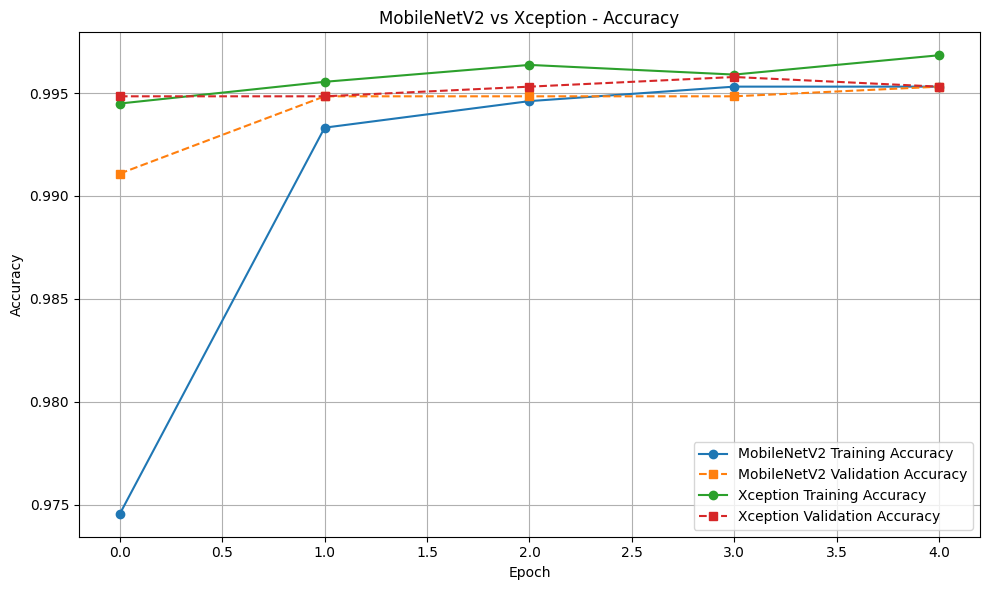

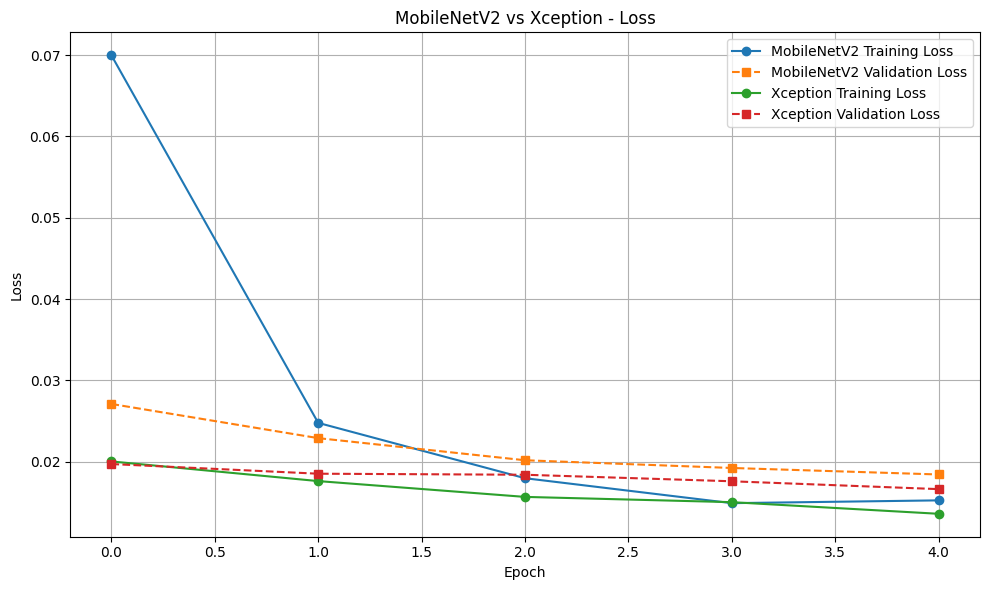

Both graphs saved successfully.


In [ ]:

import matplotlib.pyplot as plt
import os

os.makedirs("/kaggle/working/assignment_graphs", exist_ok=True)

histories = {
    "MobileNetV2": mobilenet_history,
    "Xception": xception_history
}

# Accuracy graph
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history.history["accuracy"], marker="o",
             label=f"{name} Training Accuracy")
    plt.plot(history.history["val_accuracy"], marker="s",
             linestyle="--", label=f"{name} Validation Accuracy")

plt.title("MobileNetV2 vs Xception - Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/assignment_graphs/accuracy.png", dpi=300)
plt.show()

# Loss graph
plt.figure(figsize=(10, 6))

for name, history in histories.items():
    plt.plot(history.history["loss"], marker="o",
             label=f"{name} Training Loss")
    plt.plot(history.history["val_loss"], marker="s",
             linestyle="--", label=f"{name} Validation Loss")

plt.title("MobileNetV2 vs Xception - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("/kaggle/working/assignment_graphs/loss.png", dpi=300)
plt.show()

print("Both graphs saved successfully.")


67/67 ━━━━━━━━━━━━━━━━━━━━ 2s 25ms/step - accuracy: 0.9953 - loss: 0.0184
67/67 ━━━━━━━━━━━━━━━━━━━━ 18s 269ms/step - accuracy: 0.9953 - loss: 0.0166
MobileNetV2 Validation Accuracy: 99.53%
Xception Validation Accuracy: 99.53%
67/67 ━━━━━━━━━━━━━━━━━━━━ 10s 89ms/step
67/67 ━━━━━━━━━━━━━━━━━━━━ 38s 409ms/step


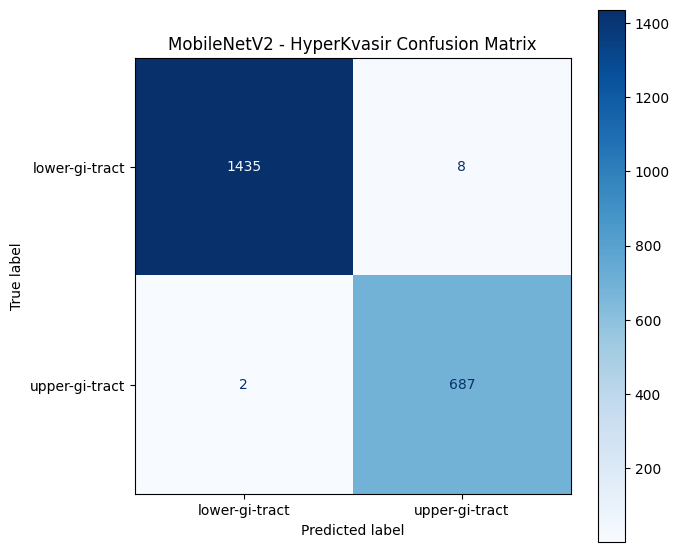


MobileNetV2 Classification Report
                precision    recall  f1-score   support

lower-gi-tract       1.00      0.99      1.00      1443
upper-gi-tract       0.99      1.00      0.99       689

      accuracy                           1.00      2132
     macro avg       0.99      1.00      0.99      2132
  weighted avg       1.00      1.00      1.00      2132



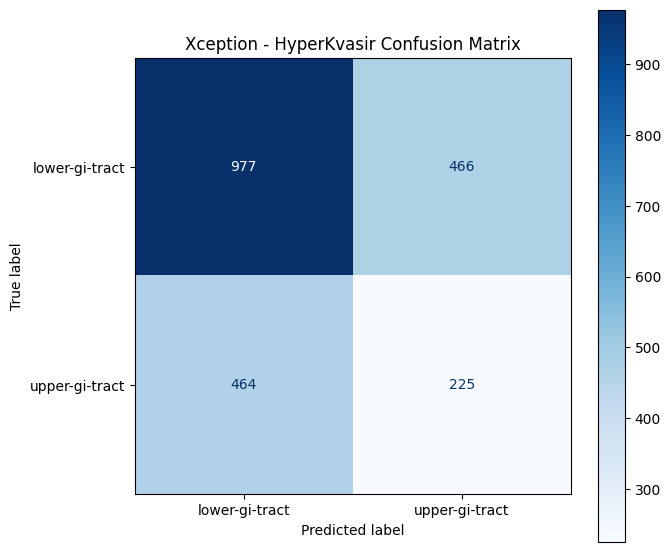


Xception Classification Report
                precision    recall  f1-score   support

lower-gi-tract       0.68      0.68      0.68      1443
upper-gi-tract       0.33      0.33      0.33       689

      accuracy                           0.56      2132
     macro avg       0.50      0.50      0.50      2132
  weighted avg       0.56      0.56      0.56      2132



In [ ]:

from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/kaggle/working/assignment_graphs"
os.makedirs(output_dir, exist_ok=True)

# Evaluate MobileNetV2
mobilenet_loss, mobilenet_acc = mobilenet_model.evaluate(val_ds, verbose=1)

# Evaluate Xception
xception_loss, xception_acc = xception_model.evaluate(xception_val_ds, verbose=1)

print(f"MobileNetV2 Validation Accuracy: {mobilenet_acc * 100:.2f}%")
print(f"Xception Validation Accuracy: {xception_acc * 100:.2f}%")

# Get true labels and predictions
y_true = np.concatenate([labels.numpy() for images, labels in val_ds])
mobilenet_pred = np.argmax(mobilenet_model.predict(val_ds, verbose=1), axis=1)
xception_pred = np.argmax(xception_model.predict(xception_val_ds, verbose=1), axis=1)

# Plot confusion matrices
for name, predictions in [
    ("MobileNetV2", mobilenet_pred),
    ("Xception", xception_pred)
]:
    cm = confusion_matrix(y_true, predictions)

    display = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_names
    )

    fig, ax = plt.subplots(figsize=(7, 6))
    display.plot(ax=ax, cmap="Blues", values_format="d")
    ax.set_title(f"{name} - HyperKvasir Confusion Matrix")
    plt.tight_layout()
    plt.savefig(f"{output_dir}/{name.lower()}_confusion_matrix.png",
                dpi=300, bbox_inches="tight")
    plt.show()

    print(f"\n{name} Classification Report")
    print(classification_report(
        y_true, predictions,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    ))


In [ ]:

import os
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2, Xception
from tensorflow.keras.callbacks import EarlyStopping

# ==========================================
# 1. DATASET SETTINGS
# ==========================================
IMAGE_FOLDER = (
    "/kaggle/input/datasets/kelkalot/"
    "the-hyper-kvasir-dataset/labeled-images"
)

IMAGE_SIZE = (224, 224)
XCEPTION_SIZE = (299, 299)
BATCH_SIZE = 32
SEED = 42
EPOCHS = 5

OUTPUT_DIR = "/kaggle/working/assignment_graphs"
os.makedirs(OUTPUT_DIR, exist_ok=True)

# ==========================================
# 2. LOAD DATA FOR MOBILENETV2
# ==========================================
train_ds = tf.keras.utils.image_dataset_from_directory(
    IMAGE_FOLDER,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

val_ds = tf.keras.utils.image_dataset_from_directory(
    IMAGE_FOLDER,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMAGE_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

class_names = train_ds.class_names
num_classes = len(class_names)

print("Classes:", class_names)
print("Number of classes:", num_classes)

# ==========================================
# 3. BUILD MOBILENETV2 MODEL
# ==========================================
mobilenet_base = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)
mobilenet_base.trainable = False

mobilenet_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    mobilenet_base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

mobilenet_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# 4. TRAIN MOBILENETV2
# ==========================================
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=2,
    restore_best_weights=True
)

mobilenet_history = mobilenet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

# ==========================================
# 5. LOAD DATA FOR XCEPTION
# ==========================================
xception_train_ds = tf.keras.utils.image_dataset_from_directory(
    IMAGE_FOLDER,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=XCEPTION_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int"
)

xception_val_ds = tf.keras.utils.image_dataset_from_directory(
    IMAGE_FOLDER,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=XCEPTION_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# ==========================================
# 6. BUILD XCEPTION MODEL
# ==========================================
xception_base = Xception(
    weights="imagenet",
    include_top=False,
    input_shape=(299, 299, 3)
)
xception_base.trainable = False

xception_model = models.Sequential([
    layers.Input(shape=(299, 299, 3)),
    layers.Rescaling(1./127.5, offset=-1),
    xception_base,
    layers.GlobalAveragePooling2D(),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation="softmax")
])

xception_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

# ==========================================
# 7. TRAIN XCEPTION
# ==========================================
xception_history = xception_model.fit(
    xception_train_ds,
    validation_data=xception_val_ds,
    epochs=EPOCHS,
    callbacks=[early_stop]
)

# ==========================================
# 8. PLOT ACCURACY AND LOSS
# ==========================================
def plot_model_history(history, model_name):
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))

    epochs = range(1, len(history.history["accuracy"]) + 1)

    axes[0].plot(
        epochs, history.history["accuracy"],
        marker="o", label="Training Accuracy"
    )
    axes[0].plot(
        epochs, history.history["val_accuracy"],
        marker="o", label="Validation Accuracy"
    )
    axes[0].set_title(f"{model_name} - Accuracy")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Accuracy")
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    axes[1].plot(
        epochs, history.history["loss"],
        marker="o", label="Training Loss"
    )
    axes[1].plot(
        epochs, history.history["val_loss"],
        marker="o", label="Validation Loss"
    )
    axes[1].set_title(f"{model_name} - Loss")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Loss")
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    fig.suptitle(f"{model_name} Training Results", fontsize=15)
    plt.tight_layout()

    filename = model_name.lower().replace(" ", "_")
    plt.savefig(
        os.path.join(OUTPUT_DIR, f"{filename}_training_curves.png"),
        dpi=300,
        bbox_inches="tight"
    )
    plt.show()

plot_model_history(mobilenet_history, "MobileNetV2")
plot_model_history(xception_history, "Xception")

# ==========================================
# 9. SAVE MODELS AND TRAINING HISTORIES
# ==========================================
mobilenet_model.save("/kaggle/working/mobilenetv2_model.keras")
xception_model.save("/kaggle/working/xception_model.keras")

import json

with open(
    os.path.join(OUTPUT_DIR, "mobilenetv2_history.json"), "w"
) as f:
    json.dump(mobilenet_history.history, f)

with open(
    os.path.join(OUTPUT_DIR, "xception_history.json"), "w"
) as f:
    json.dump(xception_history.history, f)

print("\nTraining and graph generation completed.")
print("Graphs saved in:", OUTPUT_DIR)
print("Models saved in /kaggle/working/")


In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix

xception_y_true = np.concatenate([
    labels.numpy()
    for images, labels in xception_val_ds
])

xception_y_pred = np.argmax(
    xception_model.predict(xception_val_ds, verbose=1),
    axis=1
)

print("True label counts:", np.bincount(xception_y_true))
print("Predicted label counts:", np.bincount(xception_y_pred))

accuracy = accuracy_score(xception_y_true, xception_y_pred)
print(f"Xception Accuracy: {accuracy * 100:.2f}%")

print("Confusion Matrix:")
print(confusion_matrix(xception_y_true, xception_y_pred))

67/67 ━━━━━━━━━━━━━━━━━━━━ 18s 264ms/step
True label counts: [1443  689]
Predicted label counts: [1441  691]
Xception Accuracy: 55.63%
Confusion Matrix:
[[969 474]
 [472 217]]


Xception Accuracy: 55.63%

Xception Classification Report:
                precision    recall  f1-score   support

lower-gi-tract       0.67      0.67      0.67      1443
upper-gi-tract       0.31      0.31      0.31       689

      accuracy                           0.56      2132
     macro avg       0.49      0.49      0.49      2132
  weighted avg       0.56      0.56      0.56      2132



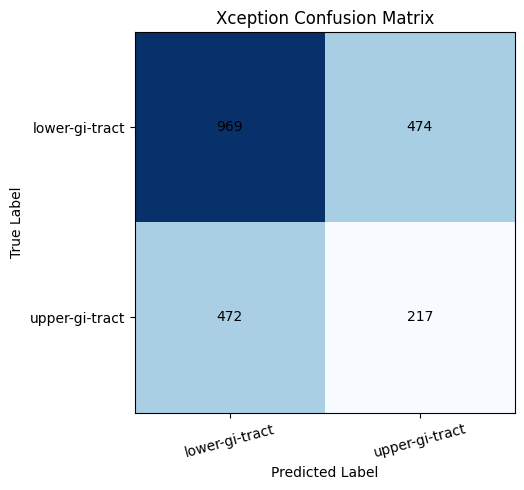

In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import numpy as np
import matplotlib.pyplot as plt
import os

output_dir = "/kaggle/working/assignment_graphs"
os.makedirs(output_dir, exist_ok=True)

# Use the predictions and labels you just verified
print("Xception Accuracy:",
      f"{accuracy_score(xception_y_true, xception_y_pred) * 100:.2f}%")

print("\nXception Classification Report:")
print(classification_report(
    xception_y_true,
    xception_y_pred,
    labels=[0, 1],
    target_names=class_names,
    zero_division=0
))

# Save corrected confusion matrix
cm = confusion_matrix(xception_y_true, xception_y_pred)
plt.figure(figsize=(7, 5))
plt.imshow(cm, cmap="Blues")
plt.title("Xception Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.xticks([0, 1], class_names, rotation=15)
plt.yticks([0, 1], class_names)

for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha="center", va="center")

plt.tight_layout()
plt.savefig(f"{output_dir}/xception_confusion_matrix_corrected.png",
            dpi=300, bbox_inches="tight")
plt.show()

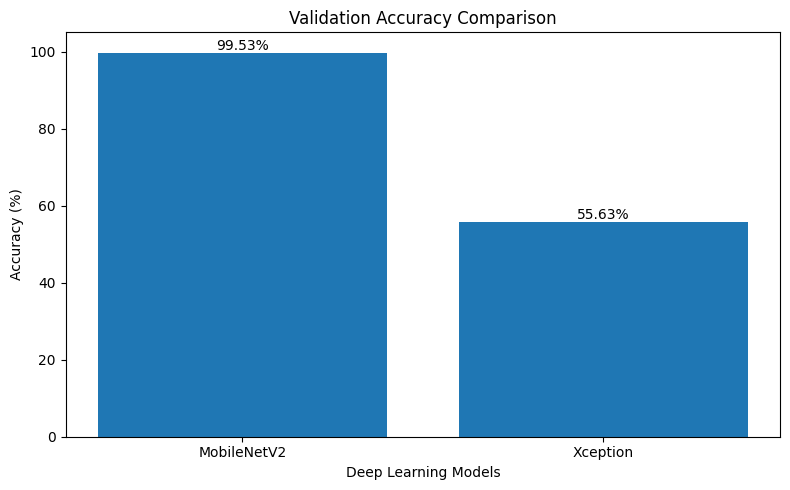

MobileNetV2: 99.53%
Xception: 55.63%


In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import os

output_dir = "/kaggle/working/assignment_graphs"
os.makedirs(output_dir, exist_ok=True)

mobilenet_accuracy = accuracy_score(y_true, mobilenet_pred) * 100
xception_accuracy = accuracy_score(
    xception_y_true, xception_y_pred
) * 100

models = ["MobileNetV2", "Xception"]
accuracies = [mobilenet_accuracy, xception_accuracy]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies)

plt.title("Validation Accuracy Comparison")
plt.xlabel("Deep Learning Models")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 105)

for bar, value in zip(bars, accuracies):
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.2f}%",
        ha="center"
    )

plt.tight_layout()
plt.savefig(
    f"{output_dir}/model_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

print(f"MobileNetV2: {mobilenet_accuracy:.2f}%")
print(f"Xception: {xception_accuracy:.2f}%")

In [ ]:
import pandas as pd
from sklearn.metrics import classification_report

mobilenet_report = classification_report(
    y_true, mobilenet_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

xception_report = classification_report(
    xception_y_true, xception_y_pred,
    target_names=class_names,
    output_dict=True,
    zero_division=0
)

results = pd.DataFrame({
    "Metric": ["Accuracy", "Precision (macro avg)",
               "Recall (macro avg)", "F1-score (macro avg)"],
    "MobileNetV2": [
        mobilenet_report["accuracy"] * 100,
        mobilenet_report["macro avg"]["precision"] * 100,
        mobilenet_report["macro avg"]["recall"] * 100,
        mobilenet_report["macro avg"]["f1-score"] * 100
    ],
    "Xception": [
        xception_report["accuracy"] * 100,
        xception_report["macro avg"]["precision"] * 100,
        xception_report["macro avg"]["recall"] * 100,
        xception_report["macro avg"]["f1-score"] * 100
    ]
})

results = results.round(2)
print(results.to_string(index=False))

               Metric  MobileNetV2  Xception
             Accuracy        99.53     55.63
Precision (macro avg)        99.35     49.32
   Recall (macro avg)        99.58     49.32
 F1-score (macro avg)        99.47     49.32


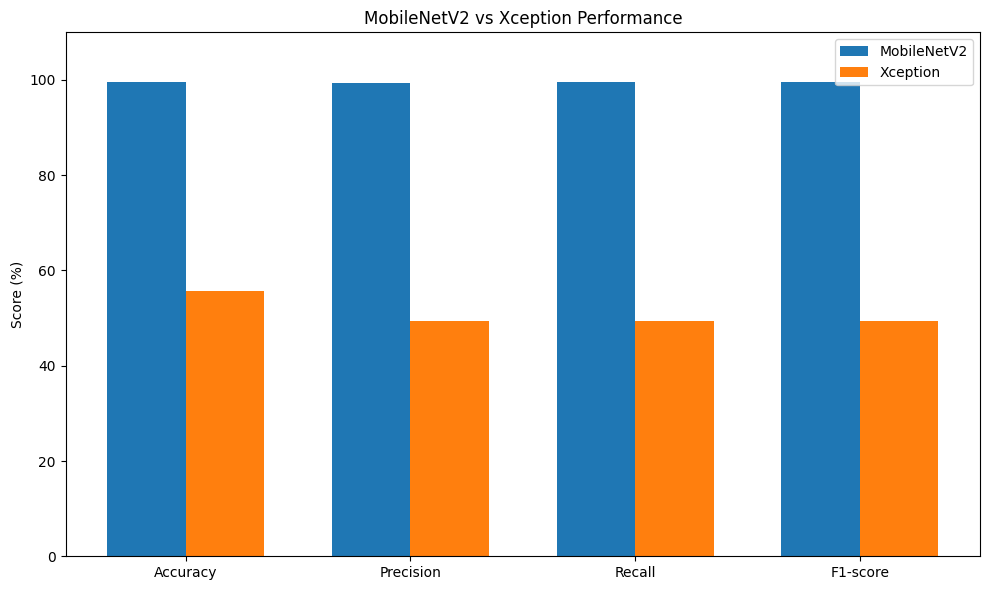

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

metrics = ["Accuracy", "Precision", "Recall", "F1-score"]

mobilenet_scores = [99.53, 99.35, 99.58, 99.47]
xception_scores = [55.63, 49.32, 49.32, 49.32]

x = np.arange(len(metrics))
width = 0.35

plt.figure(figsize=(10, 6))
plt.bar(x - width/2, mobilenet_scores, width, label="MobileNetV2")
plt.bar(x + width/2, xception_scores, width, label="Xception")

plt.title("MobileNetV2 vs Xception Performance")
plt.ylabel("Score (%)")
plt.xticks(x, metrics)
plt.ylim(0, 110)
plt.legend()
plt.tight_layout()

plt.savefig(
    "/kaggle/working/assignment_graphs/all_metrics_comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
print("MobileNetV2 input shape:", mobilenet_model.input_shape)
print("Xception input shape:", xception_model.input_shape)

print("\nMobileNetV2 preprocessing:")
print(mobilenet_model.layers[1])

print("\nXception preprocessing:")
print(xception_model.layers[1])

print("\nClass names:", class_names)

MobileNetV2 input shape: (None, 224, 224, 3)
Xception input shape: (None, 299, 299, 3)

MobileNetV2 preprocessing:
<Functional name=mobilenetv2_1.00_224, built=True>

Xception preprocessing:
<Functional name=xception, built=True>

Class names: ['lower-gi-tract', 'upper-gi-tract']


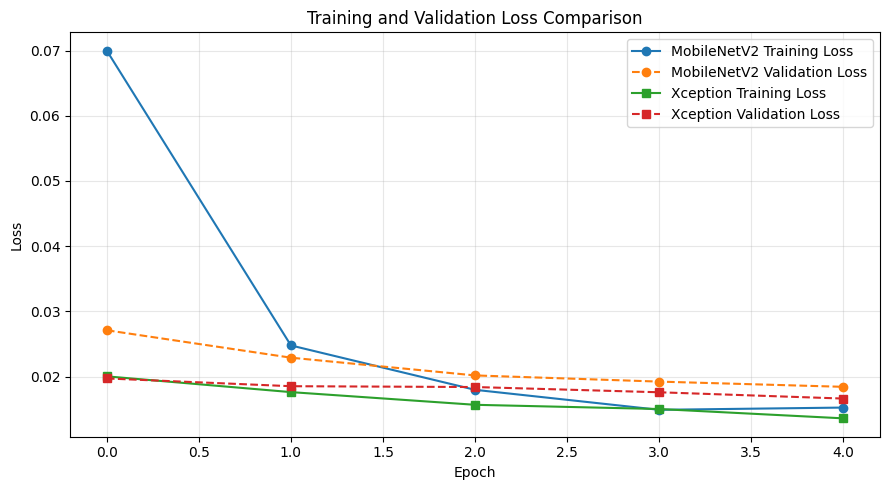

In [ ]:
import matplotlib.pyplot as plt
import os

output_dir = "/kaggle/working/assignment_graphs"
os.makedirs(output_dir, exist_ok=True)

plt.figure(figsize=(9, 5))

plt.plot(
    mobilenet_history.history["loss"],
    marker="o",
    label="MobileNetV2 Training Loss"
)
plt.plot(
    mobilenet_history.history["val_loss"],
    marker="o",
    linestyle="--",
    label="MobileNetV2 Validation Loss"
)

plt.plot(
    xception_history.history["loss"],
    marker="s",
    label="Xception Training Loss"
)
plt.plot(
    xception_history.history["val_loss"],
    marker="s",
    linestyle="--",
    label="Xception Validation Loss"
)

plt.title("Training and Validation Loss Comparison")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{output_dir}/loss_curves.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [ ]:
import pandas as pd
from sklearn.metrics import accuracy_score, precision_recall_fscore_support

def calculate_metrics(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="macro", zero_division=0
    )
    return {
        "Accuracy (%)": round(accuracy_score(y_true, y_pred) * 100, 2),
        "Precision (%)": round(precision * 100, 2),
        "Recall (%)": round(recall * 100, 2),
        "F1-score (%)": round(f1 * 100, 2)
    }

results = pd.DataFrame({
    "MobileNetV2": calculate_metrics(y_true, mobilenet_pred),
    "Xception": calculate_metrics(xception_y_true, xception_y_pred)
})

print(results)

               MobileNetV2  Xception
Accuracy (%)         99.53     55.63
Precision (%)        99.35     49.32
Recall (%)           99.58     49.32
F1-score (%)         99.47     49.32


In [ ]:
print("=" * 55)
print("HYPERKVASIR IMAGE CLASSIFICATION - RESULTS")
print("=" * 55)

print("\nDataset:")
print("Dataset: HyperKvasir")
print("Classes:", ", ".join(class_names))
print("Total images: 10,662")
print("Training images: 8,530")
print("Validation images: 2,132")

print("\nModel Comparison:")
print("-" * 55)
print(f"{'Metric':<22}{'MobileNetV2':>15}{'Xception':>15}")
print("-" * 55)

for metric in results.index:
    print(
        f"{metric:<22}"
        f"{results.loc[metric, 'MobileNetV2']:>14.2f}"
        f"{results.loc[metric, 'Xception']:>14.2f}"
    )

print("-" * 55)
print("\nNote: These are validation results, not independent test results.")

HYPERKVASIR IMAGE CLASSIFICATION - RESULTS

Dataset:
Dataset: HyperKvasir
Classes: lower-gi-tract, upper-gi-tract
Total images: 10,662
Training images: 8,530
Validation images: 2,132

Model Comparison:
-------------------------------------------------------
Metric                    MobileNetV2       Xception
-------------------------------------------------------
Accuracy (%)                   99.53         55.63
Precision (%)                  99.35         49.32
Recall (%)                     99.58         49.32
F1-score (%)                   99.47         49.32
-------------------------------------------------------

Note: These are validation results, not independent test results.
